# Logoistic regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix, classification_report
from sklearn.decomposition import PCA

# Logoistic regression  from scratch

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Check shapes
print("Feature shape: ", X.shape)
print("Target shape: ", y.shape)

Feature shape:  (569, 30)
Target shape:  (569,)


In [3]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


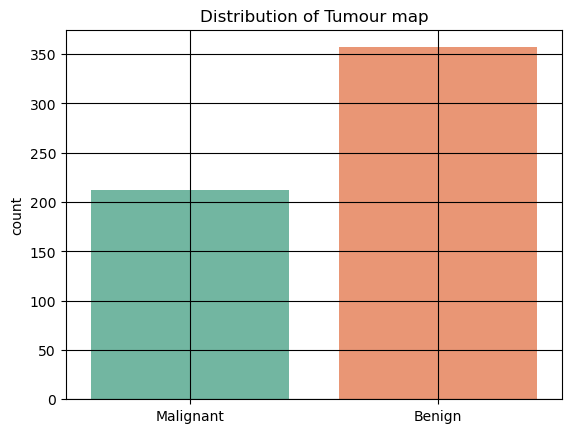

In [4]:
sns.countplot(x=y.map({0: "Malignant", 1: "Benign"}), palette='Set2')
plt.title("Distribution of Tumour map")
plt.grid(color = 'black')
plt.show()

In [5]:
# split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# standardize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train logistic Regression

In [7]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

# Model evaluation

In [8]:
# Prediction
y_pred = model.predict(X_test_scaled)

In [9]:
# Accuaccuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix: \n", cm)

# Classifcation report
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=["malignant","benign"]))

Accuracy: 0.9737
Confusion Matrix: 
 [[41  2]
 [ 1 70]]
Classification Report:
               precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        43
      benign       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [10]:
import numpy as np

# Sample dataset: 3 samples, 2 features
X = np.array([[1, 2], [3, 4], [5, 6]])

# Compute covariance matrix (rows = features)
cov_matrix = np.cov(X.T)
print(cov_matrix)


[[4. 4.]
 [4. 4.]]


# logistic regression wit PCA

In [11]:
# PCA
pca = PCA(n_components=3, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.fit_transform(X_test_scaled)
#pca_train_df = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
#pca_test_df = pd.DataFrame(X_test_pca, columns=['PC1', 'PC2'])

model = LogisticRegression(max_iter=1000)
model.fit(X_train_pca, y_train)

# Prediction
y_pred = model.predict(X_test_pca)

# Accuaccuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix: \n", cm)

# Classifcation report
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=["malignant","benign"]))

Accuracy: 0.9561
Confusion Matrix: 
 [[39  4]
 [ 1 70]]
Classification Report:
               precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        43
      benign       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



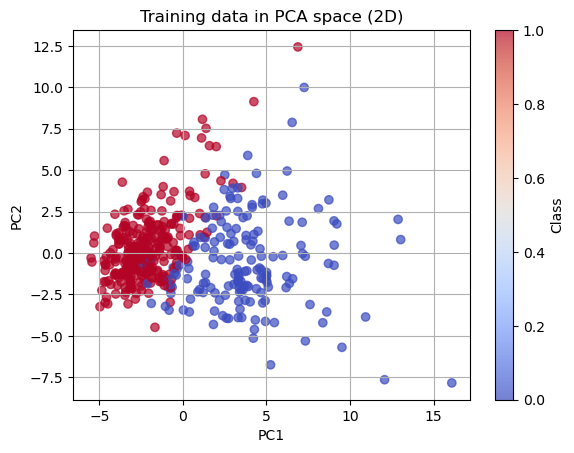

In [12]:
import matplotlib.pyplot as plt

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', alpha=0.7)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Training data in PCA space (2D)")
plt.colorbar(label='Class')
plt.grid(True)
plt.show()


In [13]:
print(pca.explained_variance_ratio_)
print("Total variance captured by 2 components:", sum(pca.explained_variance_ratio_[:]))

[0.49320955 0.16859742 0.09332234]
Total variance captured by 2 components: 0.7551293120947205


# Logistic regression from Scrach

In [14]:
# generate 2D classifcation dat
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, n_informative=2, n_clusters_per_class=1, random_state=42)

In [15]:
# Convert to Dataframe
df = pd.DataFrame(X, columns=['x1','x2'])
df['y'] = y
df.head()

,x1,x2,y
0,-0.872929,0.013042,1
1,1.312935,2.770534,1
2,2.340428,2.420996,1
3,2.294548,-0.404380,1
4,0.944105,0.477241,1


In [16]:
df.shape

(200, 3)

Text(0.5, 1.0, 'binary data classification')

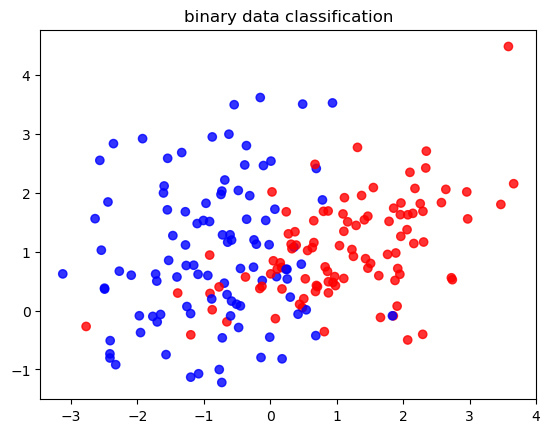

In [17]:
# plot
plt.scatter(X[:,0], X[:,1],c=y,cmap='bwr', alpha=0.8)
plt.title("binary data classification")

In [18]:
type(y)

numpy.ndarray

In [19]:
# sigmoid
def sigmoid(z):
    return 1/(1+np.exp(-z))

# Prediction
def predict_proba(X,w,b):
    return sigmoid(np.dot(X, w) + b)
def predict(X,w,b, threshold=0.5):
    return (predict_proba(X, w, b) >= threshold).astype(int)
    
# Binary
def log_loss(y_true, y_prob):
    epsilon = 1e-15
    y_prob = np.clip(y_prob, epsilon, 1-epsilon)
    return -np.mean(y_true*np.log(y_prob) + (1-y_true)*np.log(1-y_prob))

np.random.seed(1)
w = np.random.randn(2)
b = 0.0

In [20]:
# run code
def train_logistic_regression(X, y, lr =0.1, epochs = 1000):
    
    n_samples, n_features = X.shape
    w = np.random.randn(n_features)
    b = 0
    loss_history = []

    for epoch in range(epochs):
        # predictions
        y_prob = sigmoid(np.dot(X,w)+b)
        error = y_prob-y
    
        # Gradients
        dw = (1/n_samples)*np.dot(X.T,error)
        db = (1/n_samples)*np.sum(error)
    
        # update
        w -=lr*dw
        b -= lr*db
    
        # Compute and store loss
        loss = log_loss(y,y_prob)
        loss_history.append(loss)
    
        if epoch % 100 == 0:
            print(f"Epoch {epoch}: Loss = {loss:.4f}, w = {w}, b = {b:.4f}")
        
    return w, b, loss_history

In [21]:
w, b, loss_history = train_logistic_regression(X,y,lr=0.1,epochs=1000)

Epoch 0: Loss = 1.3164, w = [-0.45282046 -1.03152854], b = 0.0193
Epoch 100: Loss = 0.3772, w = [ 1.4393163  -0.34657506], b = 0.2121
Epoch 200: Loss = 0.3678, w = [ 1.72522464 -0.38482495], b = 0.1804
Epoch 300: Loss = 0.3664, w = [ 1.83857729 -0.40998355], b = 0.1809
Epoch 400: Loss = 0.3661, w = [ 1.89097194 -0.42633569], b = 0.1887
Epoch 500: Loss = 0.3660, w = [ 1.91692303 -0.43715013], b = 0.1968
Epoch 600: Loss = 0.3659, w = [ 1.93035896 -0.44431668], b = 0.2035
Epoch 700: Loss = 0.3659, w = [ 1.93756435 -0.4490537 ], b = 0.2084
Epoch 800: Loss = 0.3659, w = [ 1.9415504  -0.45217446], b = 0.2120
Epoch 900: Loss = 0.3659, w = [ 1.94381882 -0.4542243 ], b = 0.2144


In [22]:
# predict probabilty using trained weights and biases
y_probs = sigmoid(np.dot(X,w)+b)
 # predict the class labels using thresholds
y_pred = (y_probs >=0.5).astype(int)

# show first 10 results
results = pd.DataFrame({
    'x1' : X[:,0],
    'x2' : X[:,1],
    'True Label' : y,
    'Predicted_probability' : y_probs.round(3),
    'Predicted Label' : y_pred
})
results.head()

,x1,x2,True Label,Predicted_probability,Predicted Label
0,-0.872929,0.013042,1,0.184,0
1,1.312935,2.770534,1,0.819,1
2,2.340428,2.420996,1,0.975,1
3,2.294548,-0.404380,1,0.992,1
4,0.944105,0.477241,1,0.862,1


Text(0.5, 1.0, 'log.loss over')

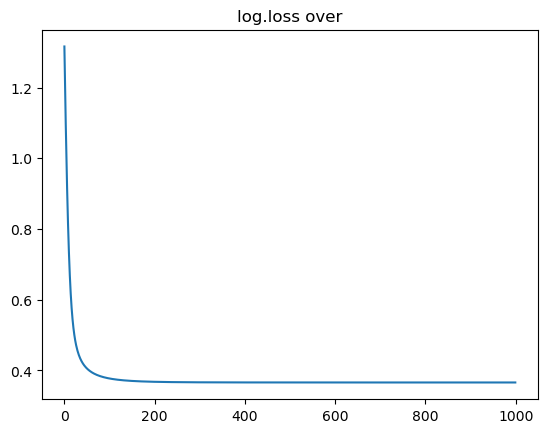

In [23]:
# plot history
plt.plot(loss_history)
plt.title("log.loss over")

In [24]:
y_pred = predict(X,w,b)
acc = accuracy_score(y, y_pred)

print(f"Accuracy: {acc:.4f}")
print("confusion Matrix:")
print(confusion_matrix(y, y_pred))

Accuracy: 0.8400
confusion Matrix:
[[83 17]
 [15 85]]


In [25]:
# Compare with logistic regression
model = LogisticRegression()
model.fit(X, y)

LogisticRegression()

In [26]:
print("Sklearn coefficient: ")

Sklearn coefficient: 


In [27]:
# recall
# precision
# Accuracy
# F1-Score
# ROC & AUC

In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix,roc_auc_score,classification_report,roc_curve,f1_score

In [29]:
y_true = np.array([3.0,-0.5,2.0,7.0])
y_pred = np.array([2.5,0.0,2.1,7.8])

In [30]:
#MAE
print("MAE: ", mean_absolute_error(y_true,y_pred))
#MSE
print("MSE: ", mean_squared_error(y_true,y_pred))
#RMAE
print("RMSE: ", mean_squared_error(y_true,y_pred, squared=False))
#R2
print("R2: ", r2_score(y_true,y_pred))

MAE:  0.475
MSE:  0.2874999999999999
RMSE:  0.5361902647381803
R2:  0.9605995717344754


# Example binary Classification

In [31]:

y_true = np.array([0,1,1,0,1,1])
y_pred = np.array([0,1,0,0,1,1])
y_prob = np.array([0.2,0.8,0.3,0.1,0.9,0.7]) ## probabilties for AUC and ROC

print("Accuracy: ", accuracy_score(y_true, y_pred))
print("Precision: ", precision_score(y_true, y_pred))
print("Recall: ", recall_score(y_true, y_pred))
print("F1 score: ", f1_score(y_true, y_pred))
print("Confusion matrix: \n",confusion_matrix(y_true, y_pred))
print("ROC AUC:",roc_auc_score(y_true, y_pred))

Accuracy:  0.8333333333333334
Precision:  1.0
Recall:  0.75
F1 score:  0.8571428571428571
Confusion matrix: 
 [[2 0]
 [1 3]]
ROC AUC: 0.875


In [32]:
print("Class report: ", classification_report(y_true,y_pred))

Class report:                precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      0.75      0.86         4

    accuracy                           0.83         6
   macro avg       0.83      0.88      0.83         6
weighted avg       0.89      0.83      0.84         6



In [33]:
print("ROC AUC:",roc_auc_score(y_true, y_pred))

ROC AUC: 0.875


In [34]:
# to find the best threshold we use AUC and ROC

In [35]:
# AUC ROC Curves
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

In [36]:
# load binary classification data
data = load_breast_cancer()
X = data.data
y = data.target #binary 0 = malignant, 1=benign


In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [38]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [39]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled,y_train)
y_pred = model.predict(X_test_scaled)

In [40]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.fit_transform(X_test_scaled)

In [41]:
model.fit(X_train_pca,y_train)
y_pred_pca = model.predict(X_test_pca)

In [50]:
# compute roc values
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred)

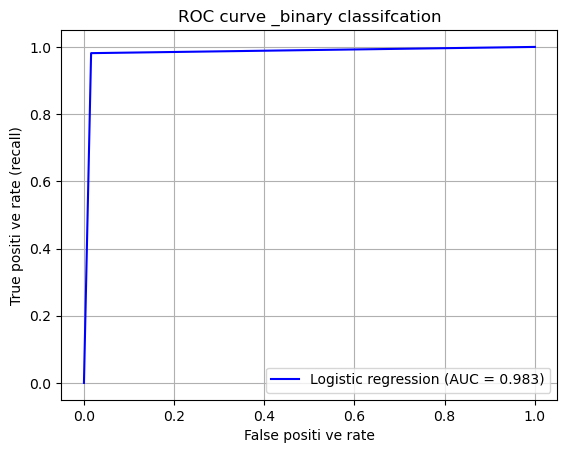

In [62]:
plt.plot(fpr, tpr, label = f"Logistic regression (AUC = {auc_score:.3f})", color = "blue")
plt.xlabel("False positi ve rate")
plt.ylabel("True positi ve rate (recall)")
plt.title("ROC curve _binary classifcation")
plt.legend()
plt.grid()
plt.show()

In [49]:
roc_auc_score(y_test, y_pred)

0.9828042328042328

In [52]:
fpr_pca, tpr_pca, thresholds_pca = roc_curve(y_test, y_pred_pca)
auc_score_pca = roc_auc_score(y_test, y_pred_pca)

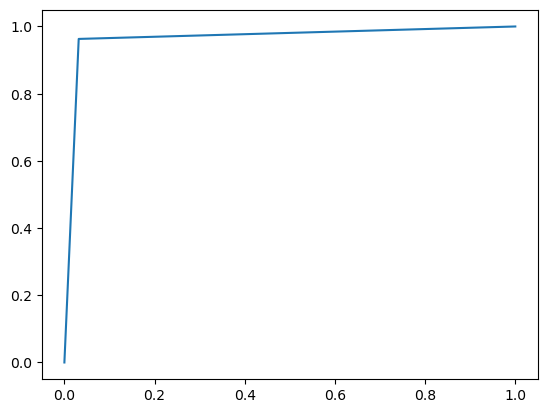

In [53]:
plt.plot(fpr_pca, tpr_pca)

In [54]:
roc_auc_score(y_test, y_pred_pca)

0.9656084656084655